In [1]:
# Install required packages
!pip install --upgrade sympy --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 65.3 MB/s eta 0:00:00:00:010:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.6.0+cu124 requires nvidia-cublas-cu12==12.4.5.8; platform_system == "Linux" and platform_machine == "x86_64", but you have nvidia-cublas-cu12 12.5.3.2 which is incompatible.
torch 2.6.0+cu124 requires nvidia-cuda-cupti-cu12==12.4.127; platform_system == "Linux" and platform_machine == "x86_64", but you have nvidia-cuda-cupti-cu12 12.5.82 which is incompatible.
torch 2.6.0+cu124 requires nvidia-cuda-nvrtc-cu12==12.4.127; platform_system == "Linux" and platform_machine == "x86_64", but you have nvidia-cuda-nvrtc-cu12 12.5.82 which is incompatible.
torch 2.6.0+cu124 requires nvidia-cuda-runtime-cu12==12.4.127; platform_system == "Linux" and platform_machine == "x86_64", but you have nvidia-cuda-runtime-cu12 12.5.82 which is

In [2]:
import timm
models = timm.list_models('*vit*')

import torch
import torch.nn as nn
from torchvision import transforms, datasets
from torch.utils.data import DataLoader, random_split
from timm import create_model
import matplotlib.pyplot as plt
from tqdm import tqdm
from collections import Counter

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [3]:
# Define transformations
transform_train = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

transform_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

In [4]:
# Create balanced dataset
import os
import random
data_dir = '/kaggle/input/nct-crc-he-100k/NCT-CRC-HE-100K'
balanced_dir = '/kaggle/working/NCT_balanced'
os.makedirs(balanced_dir, exist_ok=True)
categories = ["MUC", "TUM", "DEB", "BACK", "ADI", "MUS", "NORM", "LYM", "STR"]
target_size = 5000

for cls in categories:
    src_path = os.path.join(data_dir, cls)
    dst_path = os.path.join(balanced_dir, cls)
    os.makedirs(dst_path, exist_ok=True)
    files = os.listdir(src_path)
    if len(files) > target_size:
        selected = random.sample(files, target_size)
    else:
        selected = files.copy()
        while len(selected) < target_size:
            selected.append(random.choice(files))
    for i, f in enumerate(selected):
        src_file = os.path.join(src_path, f)
        dst_file = os.path.join(dst_path, f"{i}_{f}")
        if not os.path.exists(dst_file):
            try:
                os.symlink(src_file, dst_file)
            except FileExistsError:
                pass
print("✅ Balanced dataset created with symlinks at:", balanced_dir)


✅ Balanced dataset created with symlinks at: /kaggle/working/NCT_balanced


In [5]:
# Load dataset
dataset = datasets.ImageFolder(root="/kaggle/working/NCT_balanced", transform=transform_train)

# Print dataset details
print("Classes:", dataset.classes)
print("Class-to-Index Mapping:", dataset.class_to_idx)

# Class distribution
labels = [sample[1] for sample in dataset.samples]
print("Class Distribution:", Counter(labels))

Classes: ['ADI', 'BACK', 'DEB', 'LYM', 'MUC', 'MUS', 'NORM', 'STR', 'TUM']
Class-to-Index Mapping: {'ADI': 0, 'BACK': 1, 'DEB': 2, 'LYM': 3, 'MUC': 4, 'MUS': 5, 'NORM': 6, 'STR': 7, 'TUM': 8}
Class Distribution: Counter({0: 5000, 1: 5000, 2: 5000, 3: 5000, 4: 5000, 5: 5000, 6: 5000, 7: 5000, 8: 5000})


In [7]:
test_dataset = datasets.ImageFolder(root="/kaggle/input/crc-val-he-7k/CRC-VAL-HE-7K", transform=transform_train)

# Print dataset details
print("Classes:", test_dataset.classes)
print("Class-to-Index Mapping:", test_dataset.class_to_idx)

# Class distribution
labels = [sample[1] for sample in test_dataset.samples]
print("Class Distribution:", Counter(labels))

Classes: ['ADI', 'BACK', 'DEB', 'LYM', 'MUC', 'MUS', 'NORM', 'STR', 'TUM']
Class-to-Index Mapping: {'ADI': 0, 'BACK': 1, 'DEB': 2, 'LYM': 3, 'MUC': 4, 'MUS': 5, 'NORM': 6, 'STR': 7, 'TUM': 8}
Class Distribution: Counter({0: 1338, 8: 1233, 4: 1035, 1: 847, 6: 741, 3: 634, 5: 592, 7: 421, 2: 339})


In [8]:
# Dataset split
total_size = len(dataset)
train_size = int(0.7 * total_size)
#val_size = int(0.3 * total_size)
val_size = total_size - train_size

train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

# Apply test transformations
val_dataset.dataset.transform = transform_test
#test_dataset.dataset.transform = transform_test


# Verify split sizes
print("Train Dataset Size:", len(train_dataset))
print("Validation Dataset Size:", len(val_dataset))
print("Test Dataset Size:", len(test_dataset))

# Data loaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

Train Dataset Size: 31499
Validation Dataset Size: 13501
Test Dataset Size: 7180


Epoch 1/20


Validation: 100%|██████████| 422/422 [03:12<00:00,  2.19it/s]


Train Loss: 0.1165, Train Accuracy: 96.49%
Val Loss: 0.0532, Val Accuracy: 98.29%

Epoch 2/20


Validation: 100%|██████████| 422/422 [02:07<00:00,  3.31it/s]


Train Loss: 0.0448, Train Accuracy: 98.57%
Val Loss: 0.0964, Val Accuracy: 97.12%

Epoch 3/20


Validation: 100%|██████████| 422/422 [02:13<00:00,  3.16it/s]


Train Loss: 0.0313, Train Accuracy: 99.02%
Val Loss: 0.0849, Val Accuracy: 97.55%

Epoch 4/20


Validation: 100%|██████████| 422/422 [02:17<00:00,  3.08it/s]


Train Loss: 0.0216, Train Accuracy: 99.29%
Val Loss: 0.0773, Val Accuracy: 97.85%

Early stopping triggered. Stopping training.


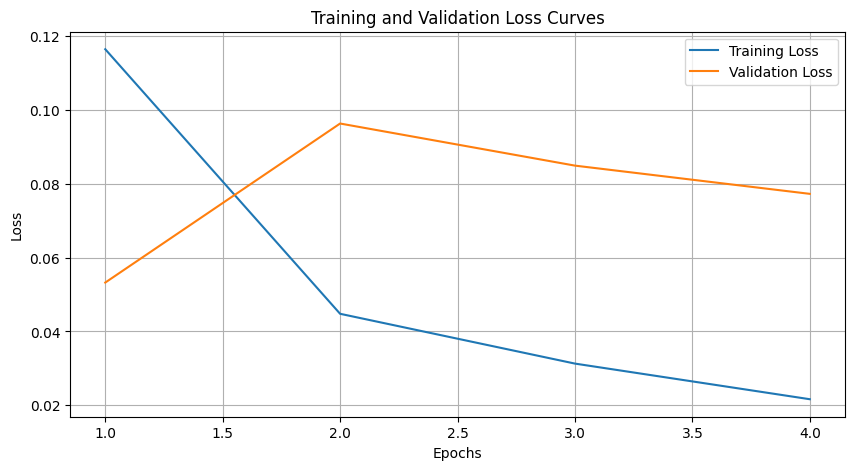

In [10]:
# Define ConViT model with dropout
class ConViTClassifier(nn.Module):
    def __init__(self, num_classes):
        super(ConViTClassifier, self).__init__()
        self.convit = create_model('convit_base', pretrained=True, num_classes=num_classes)
        self.dropout = nn.Dropout(0.0)  # Added dropout layer

    def forward(self, x):
        logits = self.convit(x)
        return self.dropout(logits)

# Load ConViT model with dropout
model = ConViTClassifier(num_classes=len(dataset.classes)).to(device)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# Early stopping class
class EarlyStopping:
    def __init__(self, patience=3, min_delta=0.001):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False

    def __call__(self, val_loss):
        if self.best_loss is None:
            self.best_loss = val_loss
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.counter = 0

# Training and validation
num_epochs = 20
train_losses, val_losses = [], []
early_stopping = EarlyStopping(patience=3)

for epoch in range(num_epochs):
    model.train()
    running_train_loss = 0.0
    train_correct = 0

    print(f"Epoch {epoch + 1}/{num_epochs}")
    for inputs, labels in tqdm(train_loader, desc="Training"):
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        # Backward pass and optimization
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        train_correct += (preds == labels).sum().item()

    train_loss = running_train_loss / len(train_loader.dataset)
    train_acc = 100.0 * train_correct / len(train_loader.dataset)
    train_losses.append(train_loss)

    # Validation (keep model in train mode to apply dropout)
    running_val_loss = 0.0
    val_correct = 0
    with torch.no_grad():
        for inputs, labels in tqdm(val_loader, desc="Validation"):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()

    val_loss = running_val_loss / len(val_loader.dataset)
    val_acc = 100.0 * val_correct / len(val_loader.dataset)
    val_losses.append(val_loss)

    print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.2f}%")
    print(f"Val Loss: {val_loss:.4f}, Val Accuracy: {val_acc:.2f}%\n")

    # Early stopping
    early_stopping(val_loss)
    if early_stopping.early_stop:
        print("Early stopping triggered. Stopping training.")
        break

# Plot loss curves
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(train_losses) + 1), train_losses, label='Training Loss')
plt.plot(range(1, len(val_losses) + 1), val_losses, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss Curves')
plt.legend()
plt.grid(True)
plt.show()



Testing: 100%|██████████| 225/225 [01:53<00:00,  1.99it/s]


Test Accuracy: 76.81%
Test Precision: 0.7992
Test Recall: 0.7681
Test F1 Score: 0.7713


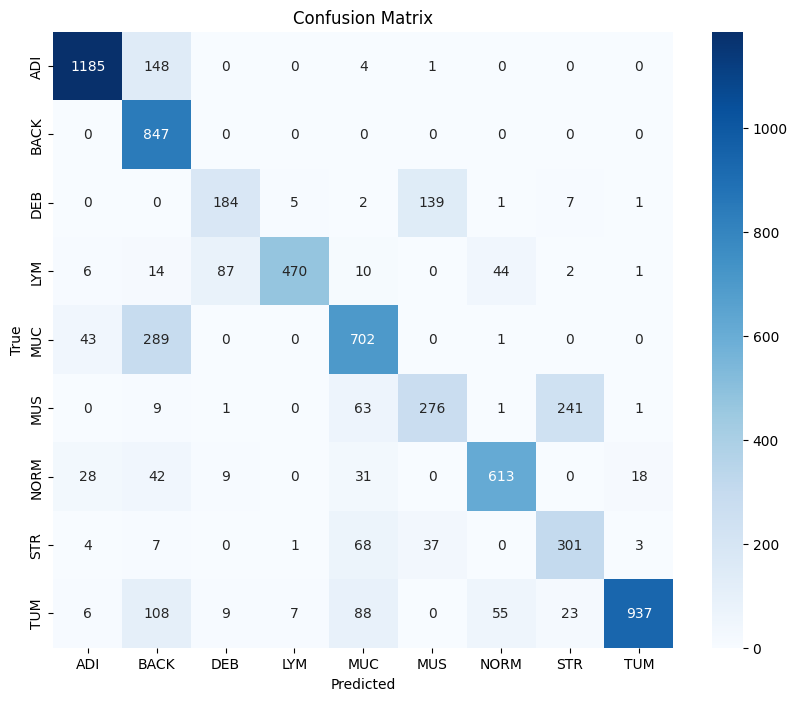

In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns
# Test model with metrics
def evaluate_model_with_metrics(model, test_loader, class_names):
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for inputs, labels in tqdm(test_loader, desc="Testing"):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    accuracy = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds, average='weighted')
    recall = recall_score(all_labels, all_preds, average='weighted')
    f1 = f1_score(all_labels, all_preds, average='weighted')

    print(f"Test Accuracy: {accuracy * 100:.2f}%")
    print(f"Test Precision: {precision:.4f}")
    print(f"Test Recall: {recall:.4f}")
    print(f"Test F1 Score: {f1:.4f}")

    # Confusion matrix
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Confusion Matrix')
    plt.show()
    

# Evaluate on test set with metrics
evaluate_model_with_metrics(model, test_loader, dataset.classes)

In [12]:
# Save the trained model with error handling
model_path = "/kaggle/working/model_ConViT.pth"
try:
    torch.save(model.state_dict(), model_path)
    print(f"Model saved successfully to {model_path}")
except Exception as e:
    print(f"Error saving model: {e}")
    raise

Model saved successfully to /kaggle/working/model_ConViT.pth


In [13]:
from IPython.display import FileLink
FileLink(r'model_ConViT.pth')

/kaggle/working/model_ConViT.pth

In [ ]:
# Load ConViT model with dropout
model = ConViTClassifier(num_classes=len(dataset.classes)).to(device)
eff_state = torch.load('/kaggle/input/convit2/pytorch/default/1/model_ConViT (1).pth', map_location=device)
model_state = model.state_dict()
for k, v in eff_state.items():
    if k in model_state and model_state[k].shape == v.shape:
        model_state[k] = v
model.load_state_dict(model_state, strict=False)
model = model.to(device)

In [14]:
!pip install grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 66.7 MB/s eta 0:00:0000:0100:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 93.3 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 75.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 42.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 2.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 10.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 13.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 8.2

In [15]:
# Explicitly import pytorch_grad_cam components
try:
    from pytorch_grad_cam import GradCAM
    from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
    from pytorch_grad_cam.utils.image import show_cam_on_image
except ImportError as e:
    print(f"Error importing pytorch_grad_cam: {e}")
    print("Ensure 'grad-cam' is installed correctly with: !pip install grad-cam")
    raise

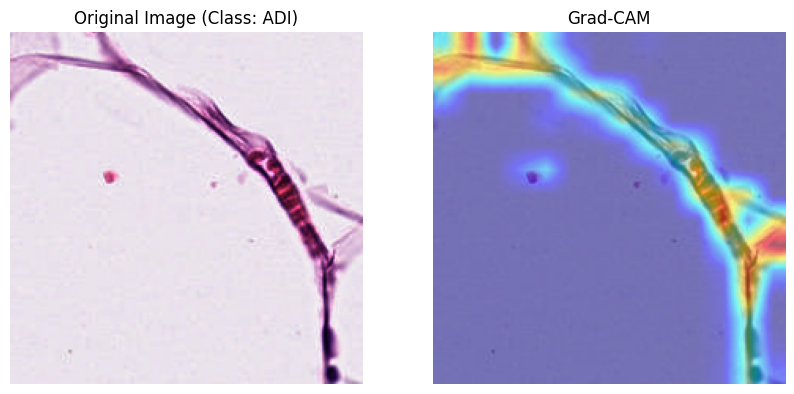

Grad-CAM plot saved to /kaggle/working/gradcam_convit_ADI-TCGA-AAICEQFN.tif.png


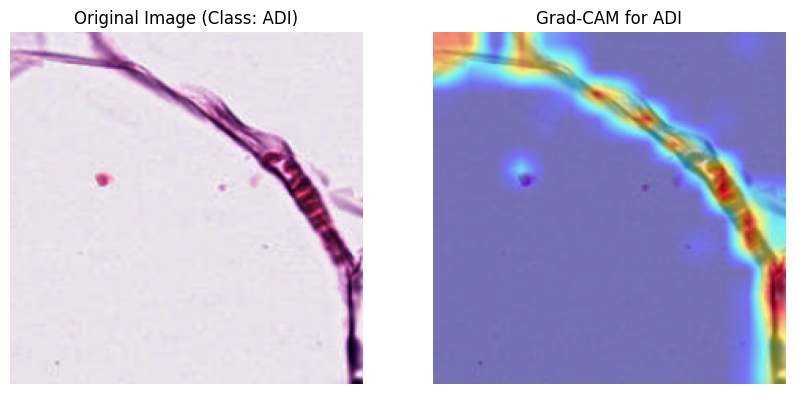

Grad-CAM for label ADI saved to /kaggle/working/gradcam_convit_label_ADI.png


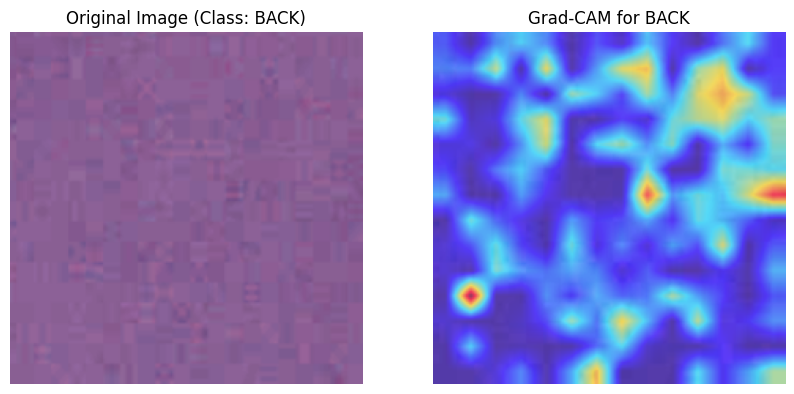

Grad-CAM for label BACK saved to /kaggle/working/gradcam_convit_label_BACK.png


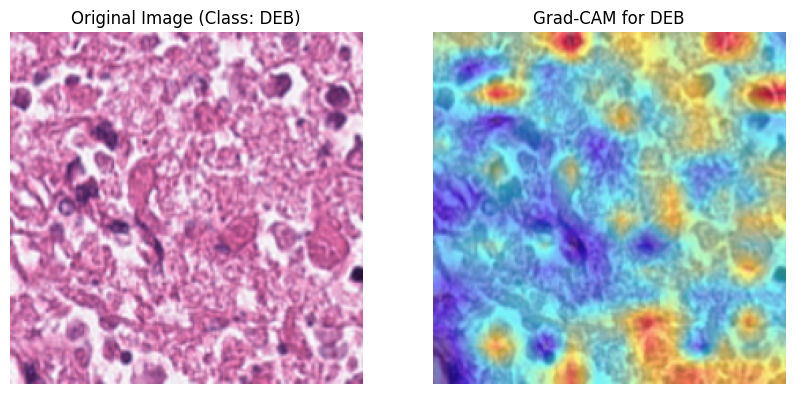

Grad-CAM for label DEB saved to /kaggle/working/gradcam_convit_label_DEB.png


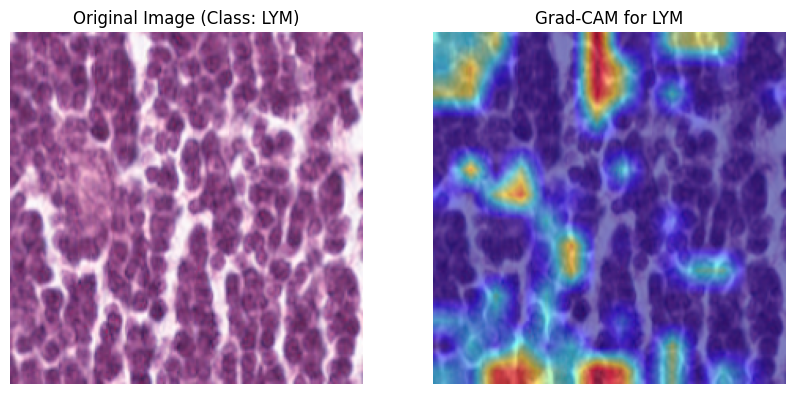

Grad-CAM for label LYM saved to /kaggle/working/gradcam_convit_label_LYM.png


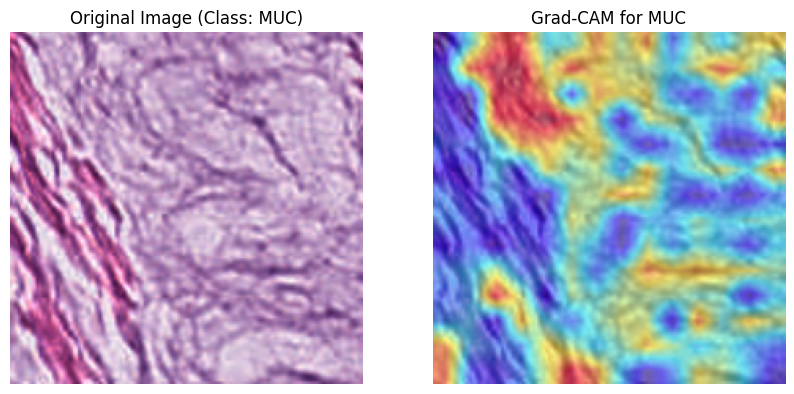

Grad-CAM for label MUC saved to /kaggle/working/gradcam_convit_label_MUC.png


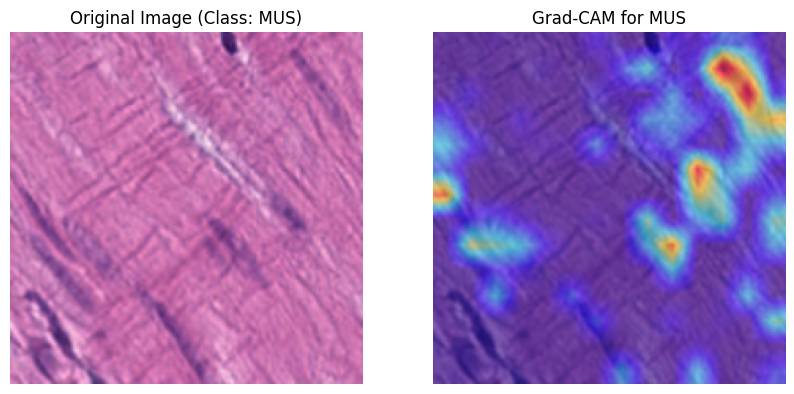

Grad-CAM for label MUS saved to /kaggle/working/gradcam_convit_label_MUS.png


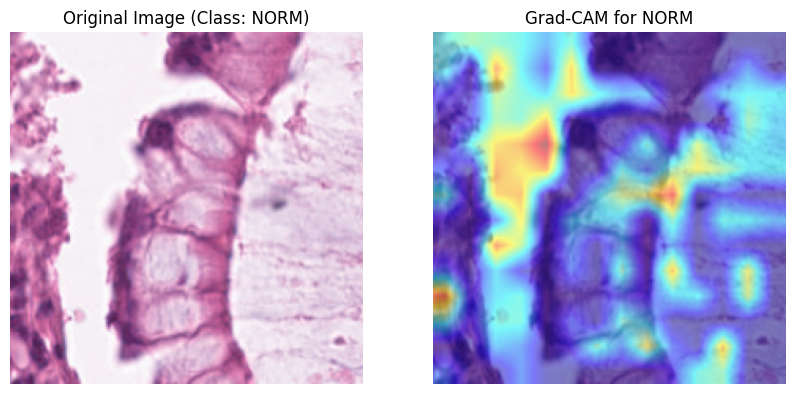

Grad-CAM for label NORM saved to /kaggle/working/gradcam_convit_label_NORM.png


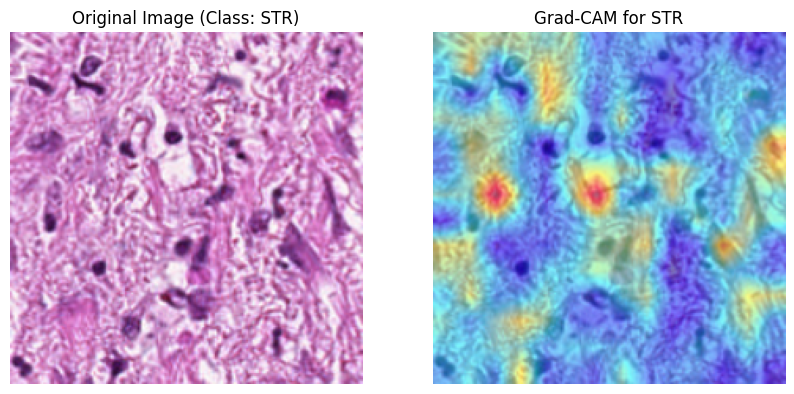

Grad-CAM for label STR saved to /kaggle/working/gradcam_convit_label_STR.png


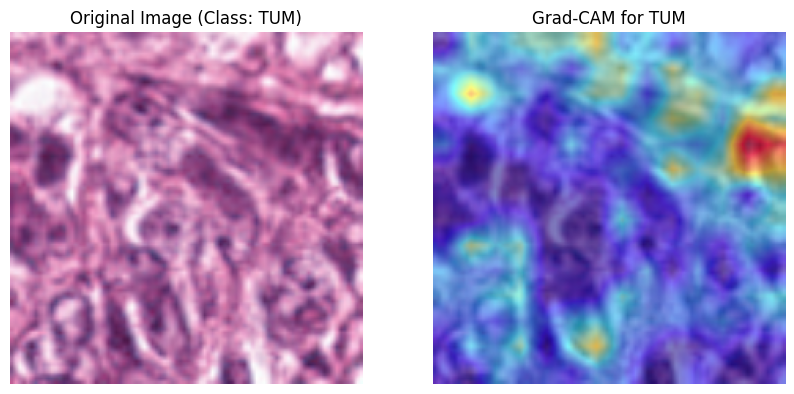

Grad-CAM for label TUM saved to /kaggle/working/gradcam_convit_label_TUM.png


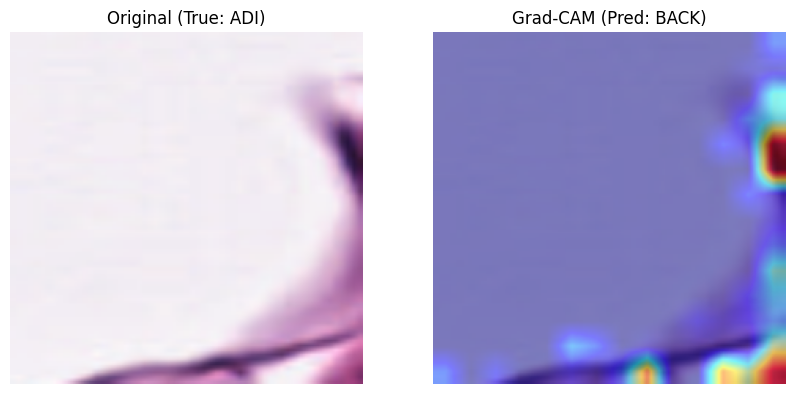

Grad-CAM for incorrect ADI (pred: BACK) saved to /kaggle/working/gradcam_convit_incorrect_ADI.png
No incorrect predictions found for class BACK. Skipping Grad-CAM.


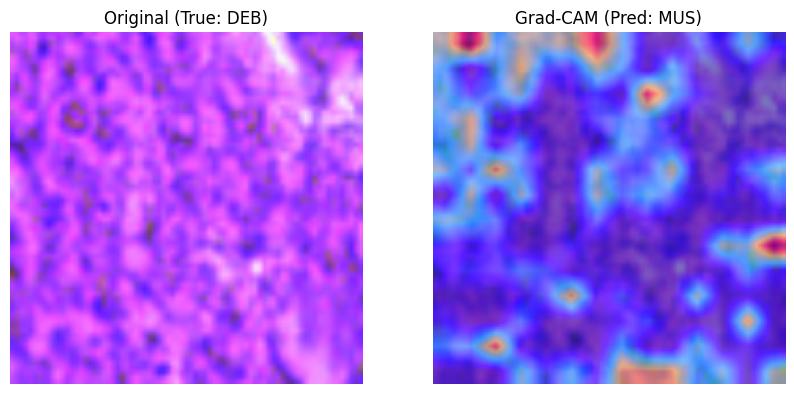

Grad-CAM for incorrect DEB (pred: MUS) saved to /kaggle/working/gradcam_convit_incorrect_DEB.png


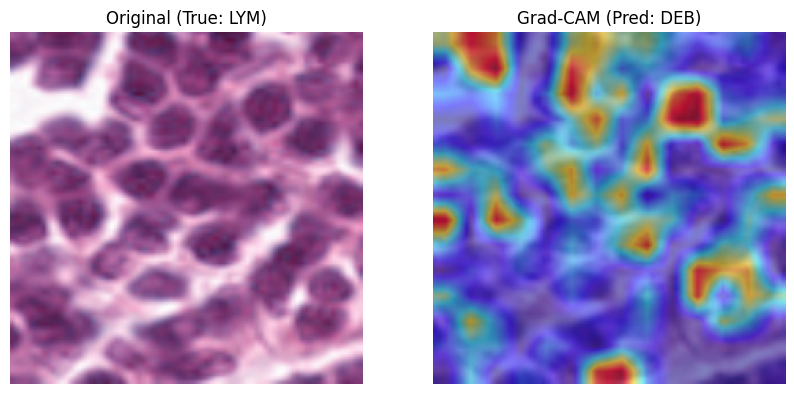

Grad-CAM for incorrect LYM (pred: DEB) saved to /kaggle/working/gradcam_convit_incorrect_LYM.png


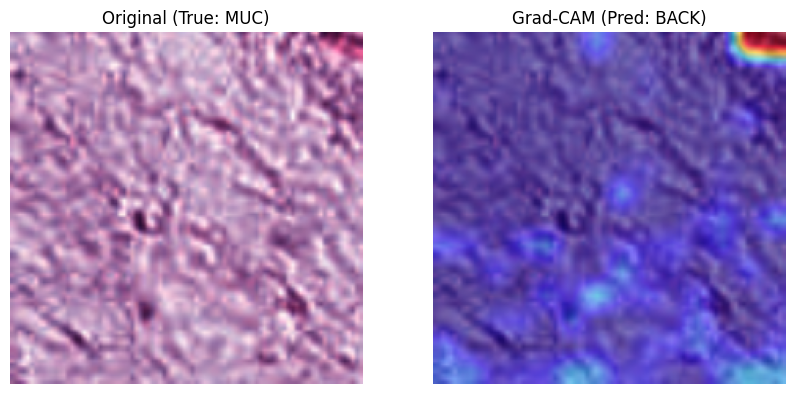

Grad-CAM for incorrect MUC (pred: BACK) saved to /kaggle/working/gradcam_convit_incorrect_MUC.png


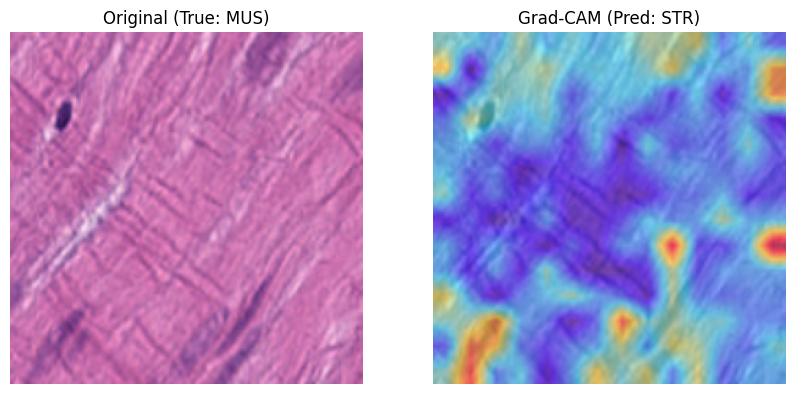

Grad-CAM for incorrect MUS (pred: STR) saved to /kaggle/working/gradcam_convit_incorrect_MUS.png


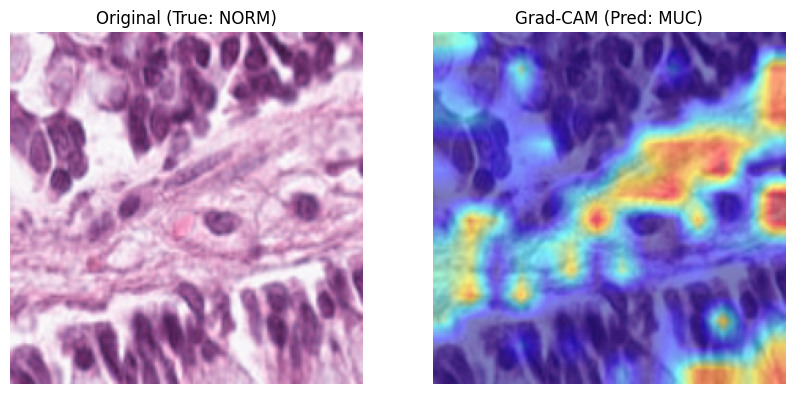

Grad-CAM for incorrect NORM (pred: MUC) saved to /kaggle/working/gradcam_convit_incorrect_NORM.png


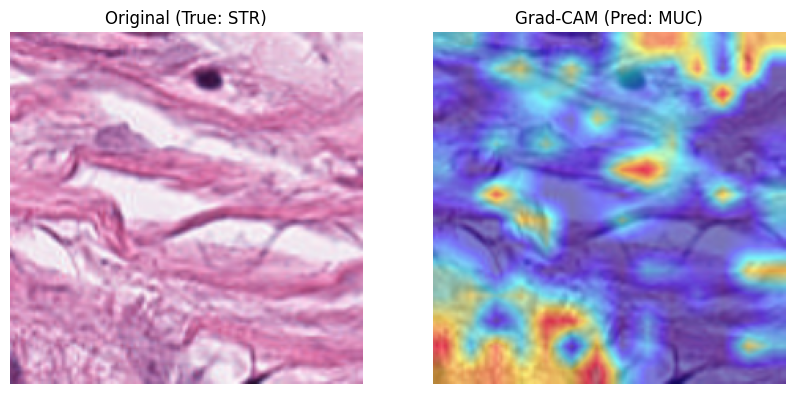

Grad-CAM for incorrect STR (pred: MUC) saved to /kaggle/working/gradcam_convit_incorrect_STR.png


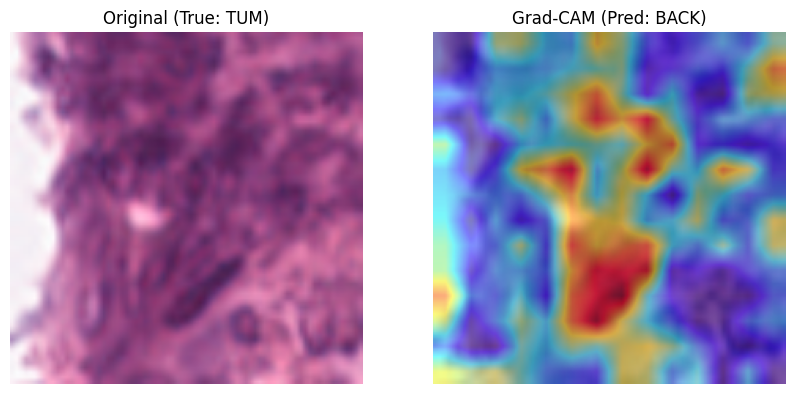

Grad-CAM for incorrect TUM (pred: BACK) saved to /kaggle/working/gradcam_convit_incorrect_TUM.png


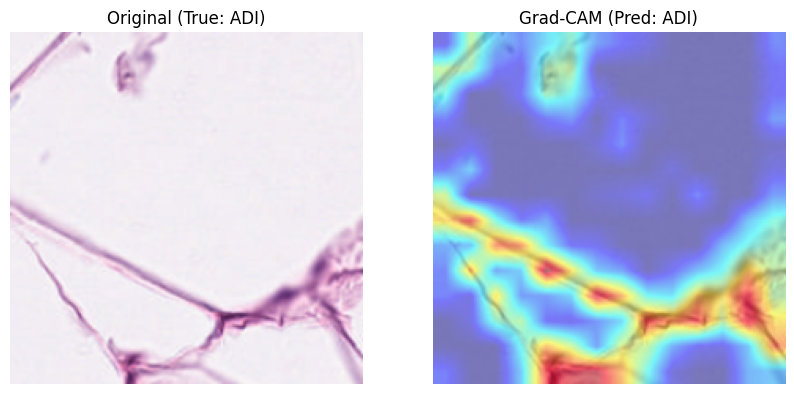

Grad-CAM for random correct ADI saved to /kaggle/working/gradcam_convit_random_correct_ADI.png


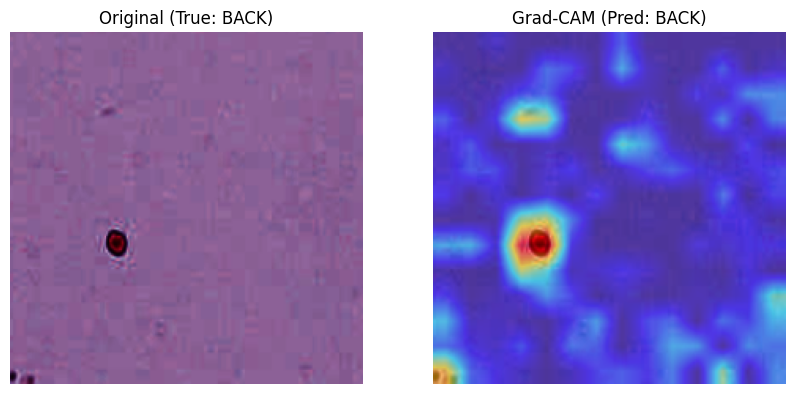

Grad-CAM for random correct BACK saved to /kaggle/working/gradcam_convit_random_correct_BACK.png


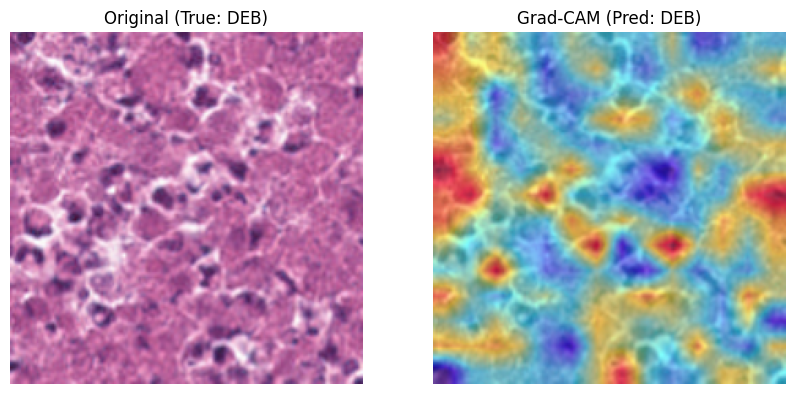

Grad-CAM for random correct DEB saved to /kaggle/working/gradcam_convit_random_correct_DEB.png


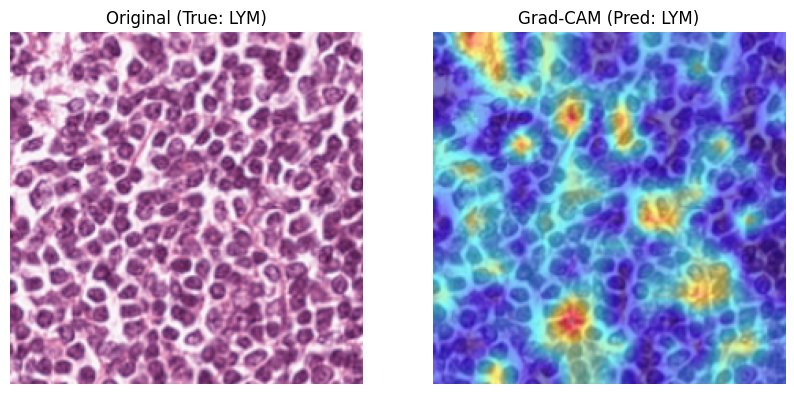

Grad-CAM for random correct LYM saved to /kaggle/working/gradcam_convit_random_correct_LYM.png


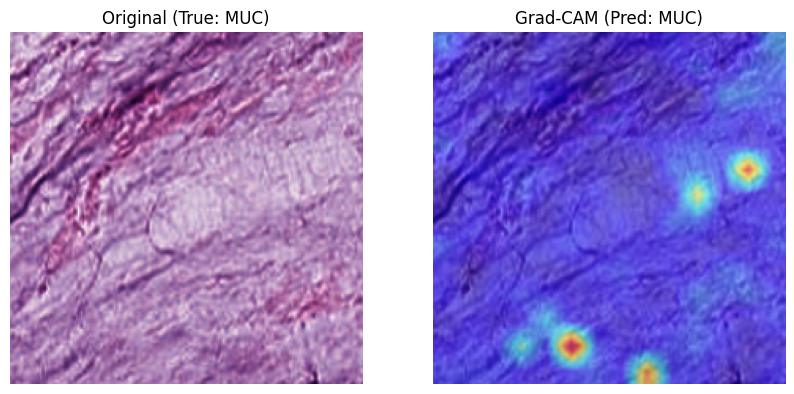

Grad-CAM for random correct MUC saved to /kaggle/working/gradcam_convit_random_correct_MUC.png


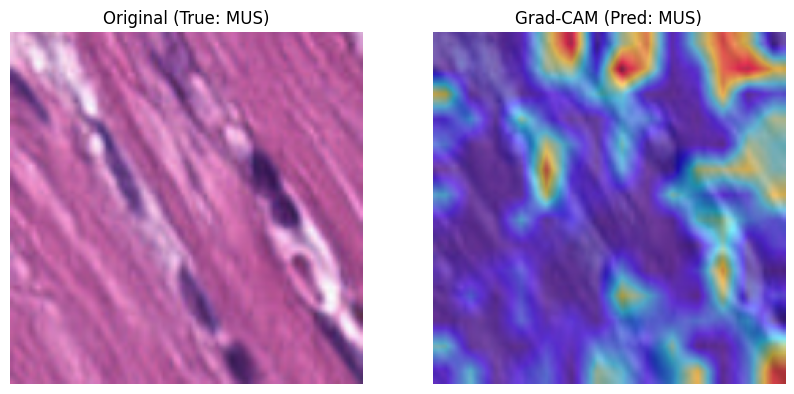

Grad-CAM for random correct MUS saved to /kaggle/working/gradcam_convit_random_correct_MUS.png


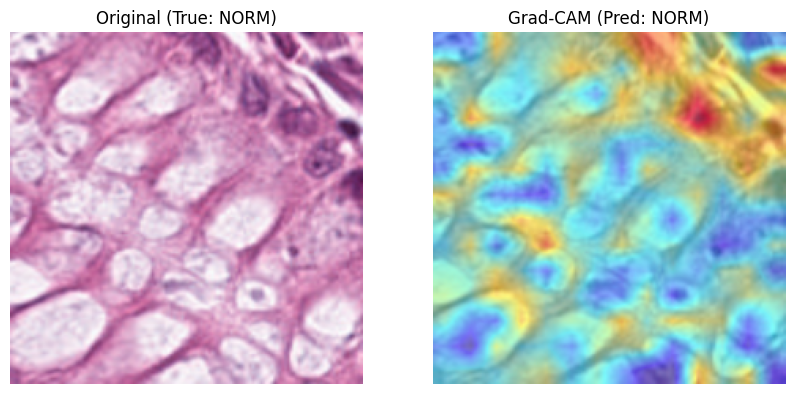

Grad-CAM for random correct NORM saved to /kaggle/working/gradcam_convit_random_correct_NORM.png


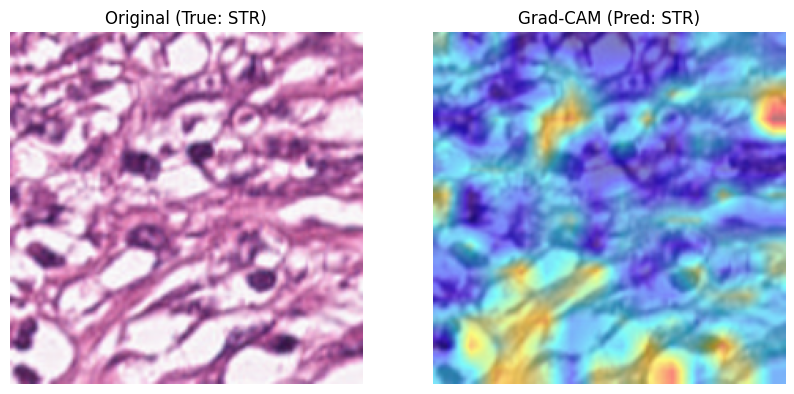

Grad-CAM for random correct STR saved to /kaggle/working/gradcam_convit_random_correct_STR.png


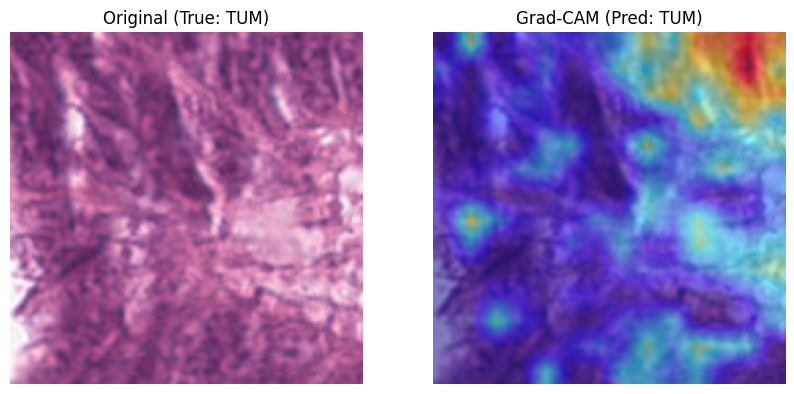

Grad-CAM for random correct TUM saved to /kaggle/working/gradcam_convit_random_correct_TUM.png


In [17]:
# Grad-CAM implementation for ConViT
import numpy as np
from PIL import Image

# Wrapper class for ConViT model
class ConViTModelWrapper(torch.nn.Module):
    def __init__(self, model):
        super(ConViTModelWrapper, self).__init__()
        self.model = model

    def forward(self, x):
        return self.model(x)

# Reshape transform for ConViT
def reshape_transform_convit(x):
    activations = x[:, 1:, :]  # Remove CLS token: (B, 197, hidden) -> (B, 196, hidden)
    activations = activations.view(activations.shape[0], 14, 14, activations.shape[2])  # Reshape to (B, 14, 14, hidden)
    activations = activations.permute(0, 3, 1, 2)  # To (B, hidden, 14, 14)
    return activations

# Data transform for Grad-CAM
data_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Denormalize function for visualization
def denormalize(tensor):
    mean = np.array([0.5, 0.5, 0.5])
    std = np.array([0.5, 0.5, 0.5])
    tensor = tensor.cpu().numpy().transpose((1, 2, 0))
    tensor = std * tensor + mean
    tensor = np.clip(tensor, 0, 1)
    return tensor

# Load trained ConViT model
model = ConViTClassifier(num_classes=len(dataset.classes)).to(device)
try:
    convit_state = torch.load('/kaggle/working/model_ConViT.pth', map_location=device)
    model_state = model.state_dict()
    for k, v in convit_state.items():
        if k in model_state and model_state[k].shape == v.shape:
            model_state[k] = v
    model.load_state_dict(model_state, strict=False)
    model.eval()
except FileNotFoundError:
    print("Error: Trained model file '/kaggle/working/model_ConViT.pth' not found. Please ensure the model is saved.")
    raise

# Target layer: second-to-last transformer block output
target_layer = model.convit.blocks[-2]

# Visualize Grad-CAM for a sample image
def visualize_gradcam(image_path, model, target_layer, target_class):
    wrapper = ConViTModelWrapper(model)
    cam = GradCAM(model=wrapper, target_layers=[target_layer], reshape_transform=reshape_transform_convit)
    
    image = Image.open(image_path).convert('RGB')
    input_tensor = data_transform(image).unsqueeze(0).to(device)
    targets = [ClassifierOutputTarget(target_class)]
    
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
    input_image = denormalize(input_tensor[0])
    visualization = show_cam_on_image(input_image, grayscale_cam, use_rgb=True)
    
    class_name = [k for k, v in dataset.class_to_idx.items() if v == target_class][0]
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(input_image)
    plt.title(f"Original Image (Class: {class_name})")
    plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.imshow(visualization)
    plt.title("Grad-CAM")
    plt.axis('off')
    plt.savefig(f'/kaggle/working/gradcam_convit_{os.path.basename(image_path)}.png', format='png', dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Grad-CAM plot saved to /kaggle/working/gradcam_convit_{os.path.basename(image_path)}.png")

# Generate Grad-CAM for one correctly predicted image per label
def generate_gradcam_per_label(model, dataloader, target_layer, class_to_idx):
    wrapper = ConViTModelWrapper(model)
    cam = GradCAM(model=wrapper, target_layers=[target_layer], reshape_transform=reshape_transform_convit)
    
    correct_samples = {label: None for label in class_to_idx.values()}
    model.eval()
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            for i in range(inputs.size(0)):
                label = labels[i].item()
                if preds[i].item() == label and correct_samples[label] is None:
                    correct_samples[label] = (inputs[i].unsqueeze(0), label)
            if all(v is not None for v in correct_samples.values()):
                break
    
    for label, (input_tensor, label_idx) in correct_samples.items():
        if input_tensor is not None:
            targets = [ClassifierOutputTarget(label_idx)]
            grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
            
            input_image = denormalize(input_tensor[0])
            visualization = show_cam_on_image(input_image, grayscale_cam, use_rgb=True)
            
            class_name = [k for k, v in class_to_idx.items() if v == label_idx][0]
            plt.figure(figsize=(10, 5))
            plt.subplot(1, 2, 1)
            plt.imshow(input_image)
            plt.title(f"Original Image (Class: {class_name})")
            plt.axis('off')
            plt.subplot(1, 2, 2)
            plt.imshow(visualization)
            plt.title(f"Grad-CAM for {class_name}")
            plt.axis('off')
            plt.savefig(f'/kaggle/working/gradcam_convit_label_{class_name}.png', format='png', dpi=300, bbox_inches='tight')
            plt.show()
            print(f"Grad-CAM for label {class_name} saved to /kaggle/working/gradcam_convit_label_{class_name}.png")

# Generate Grad-CAM for incorrect predictions
def generate_gradcam_for_incorrect(model, dataloader, target_layer, class_to_idx):
    wrapper = ConViTModelWrapper(model)
    cam = GradCAM(model=wrapper, target_layers=[target_layer], reshape_transform=reshape_transform_convit)
    
    incorrect_samples = {label: None for label in class_to_idx.values()}
    model.eval()
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            for i in range(inputs.size(0)):
                label = labels[i].item()
                if preds[i].item() != label and incorrect_samples[label] is None:
                    incorrect_samples[label] = (inputs[i].unsqueeze(0), preds[i].item(), label)
    
    for true_label, sample in incorrect_samples.items():
        if sample is None:
            class_name = [k for k, v in class_to_idx.items() if v == true_label][0]
            print(f"No incorrect predictions found for class {class_name}. Skipping Grad-CAM.")
            continue
        input_tensor, pred_label, _ = sample
        targets = [ClassifierOutputTarget(pred_label)]
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
        
        input_image = denormalize(input_tensor[0])
        visualization = show_cam_on_image(input_image, grayscale_cam, use_rgb=True)
        
        true_class = [k for k, v in class_to_idx.items() if v == true_label][0]
        pred_class = [k for k, v in class_to_idx.items() if v == pred_label][0]
        plt.figure(figsize=(10, 5))
        plt.subplot(1, 2, 1)
        plt.imshow(input_image)
        plt.title(f"Original (True: {true_class})")
        plt.axis('off')
        plt.subplot(1, 2, 2)
        plt.imshow(visualization)
        plt.title(f"Grad-CAM (Pred: {pred_class})")
        plt.axis('off')
        plt.savefig(f'/kaggle/working/gradcam_convit_incorrect_{true_class}.png', format='png', dpi=300, bbox_inches='tight')
        plt.show()
        print(f"Grad-CAM for incorrect {true_class} (pred: {pred_class}) saved to /kaggle/working/gradcam_convit_incorrect_{true_class}.png")

# Generate Grad-CAM for random correct predictions
def generate_gradcam_for_random_correct(model, dataloader, target_layer, class_to_idx):
    wrapper = ConViTModelWrapper(model)
    cam = GradCAM(model=wrapper, target_layers=[target_layer], reshape_transform=reshape_transform_convit)
    
    correct_samples = {label: [] for label in class_to_idx.values()}
    model.eval()
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            for i in range(inputs.size(0)):
                label = labels[i].item()
                if preds[i].item() == label:
                    correct_samples[label].append((inputs[i].unsqueeze(0), label))
    
    random_correct_samples = {
        label: random.choice(samples) if samples else None for label, samples in correct_samples.items()
    }
    
    for label, sample in random_correct_samples.items():
        if sample is not None:
            input_tensor, true_label = sample
            targets = [ClassifierOutputTarget(true_label)]
            grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
            
            input_image = denormalize(input_tensor[0])
            visualization = show_cam_on_image(input_image, grayscale_cam, use_rgb=True)
            
            class_name = [k for k, v in class_to_idx.items() if v == true_label][0]
            plt.figure(figsize=(10, 5))
            plt.subplot(1, 2, 1)
            plt.imshow(input_image)
            plt.title(f"Original (True: {class_name})")
            plt.axis('off')
            plt.subplot(1, 2, 2)
            plt.imshow(visualization)
            plt.title(f"Grad-CAM (Pred: {class_name})")
            plt.axis('off')
            plt.savefig(f'/kaggle/working/gradcam_convit_random_correct_{class_name}.png', format='png', dpi=300, bbox_inches='tight')
            plt.show()
            print(f"Grad-CAM for random correct {class_name} saved to /kaggle/working/gradcam_convit_random_correct_{class_name}.png")

# Generate Grad-CAM visualizations
sample_image_path = test_dataset.samples[0][0]
sample_class = test_dataset.samples[0][1]
visualize_gradcam(sample_image_path, model, target_layer, sample_class)
generate_gradcam_per_label(model, test_loader, target_layer, dataset.class_to_idx)
generate_gradcam_for_incorrect(model, test_loader, target_layer, dataset.class_to_idx)
generate_gradcam_for_random_correct(model, test_loader, target_layer, dataset.class_to_idx)